In [1]:
import pandas as pd
import numpy as np
import sqlite3

df = pd.read_csv("cookie_cats.csv")
print(df.shape)
print(df.head())
print(df.dtypes)
print(df.isnull().sum())

(90189, 5)
   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True
userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64


In [2]:
# Load into SQLite
conn = sqlite3.connect("cookie_cats.db")
df.to_sql("players", conn, if_exists="replace", index=False)

# Quick SQL query: player count and average rounds per group
query = """
SELECT version,
       COUNT(*) AS num_players,
       AVG(sum_gamerounds) AS avg_rounds,
       AVG(CAST(retention_1 AS INT)) AS retention_1_rate,
       AVG(CAST(retention_7 AS INT)) AS retention_7_rate
FROM players
GROUP BY version
"""

result = pd.read_sql(query, conn)
print(result)

   version  num_players  avg_rounds  retention_1_rate  retention_7_rate
0  gate_30        44700   52.456264          0.448188          0.190201
1  gate_40        45489   51.298776          0.442283          0.182000


In [3]:
# Check for outliers in sum_gamerounds
print(df['sum_gamerounds'].describe())
print("\nTop 5 highest round counts:")
print(df.sort_values('sum_gamerounds', ascending=False).head())

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

Top 5 highest round counts:
        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  gate_30           49854        False         True
7912    871500  gate_30            2961         True         True
29417  3271615  gate_40            2640         True        False
43671  4832608  gate_30            2438         True         True
48188  5346171  gate_40            2294         True         True


In [4]:
# Exclude the extreme outlier
df_clean = df[df['sum_gamerounds'] < 49854].copy()
print(f"Removed {len(df) - len(df_clean)} outlier(s). New shape: {df_clean.shape}")

Removed 1 outlier(s). New shape: (90188, 5)


In [5]:
from scipy.stats import chi2_contingency

# --- 1-day retention test ---
contingency_1 = pd.crosstab(df_clean['version'], df_clean['retention_1'])
chi2_1, p_1, dof_1, expected_1 = chi2_contingency(contingency_1)

print("1-day retention contingency table:")
print(contingency_1)
print(f"\nChi-square statistic: {chi2_1:.4f}")
print(f"p-value: {p_1:.4f}")
print(f"Significant at 0.05? {'Yes' if p_1 < 0.05 else 'No'}")

print("\n" + "="*50 + "\n")

# --- 7-day retention test ---
contingency_7 = pd.crosstab(df_clean['version'], df_clean['retention_7'])
chi2_7, p_7, dof_7, expected_7 = chi2_contingency(contingency_7)

print("7-day retention contingency table:")
print(contingency_7)
print(f"\nChi-square statistic: {chi2_7:.4f}")
print(f"p-value: {p_7:.4f}")
print(f"Significant at 0.05? {'Yes' if p_7 < 0.05 else 'No'}")

1-day retention contingency table:
retention_1  False  True 
version                  
gate_30      24665  20034
gate_40      25370  20119

Chi-square statistic: 3.1698
p-value: 0.0750
Significant at 0.05? No


7-day retention contingency table:
retention_7  False  True 
version                  
gate_30      36198   8501
gate_40      37210   8279

Chi-square statistic: 9.9153
p-value: 0.0016
Significant at 0.05? Yes


In [6]:
# Segment players by engagement level based on rounds played
df_clean['engagement_level'] = pd.qcut(
    df_clean['sum_gamerounds'], 
    q=3, 
    labels=['Low', 'Medium', 'High']
)

# Retention_7 rate by engagement level and version
segment_summary = df_clean.groupby(['engagement_level', 'version'], observed=True)['retention_7'].mean().unstack()
segment_summary['difference'] = segment_summary['gate_30'] - segment_summary['gate_40']
print(segment_summary)

version            gate_30   gate_40  difference
engagement_level                                
Low               0.015407  0.016354   -0.000947
Medium            0.086784  0.079728    0.007055
High              0.476555  0.463823    0.012732


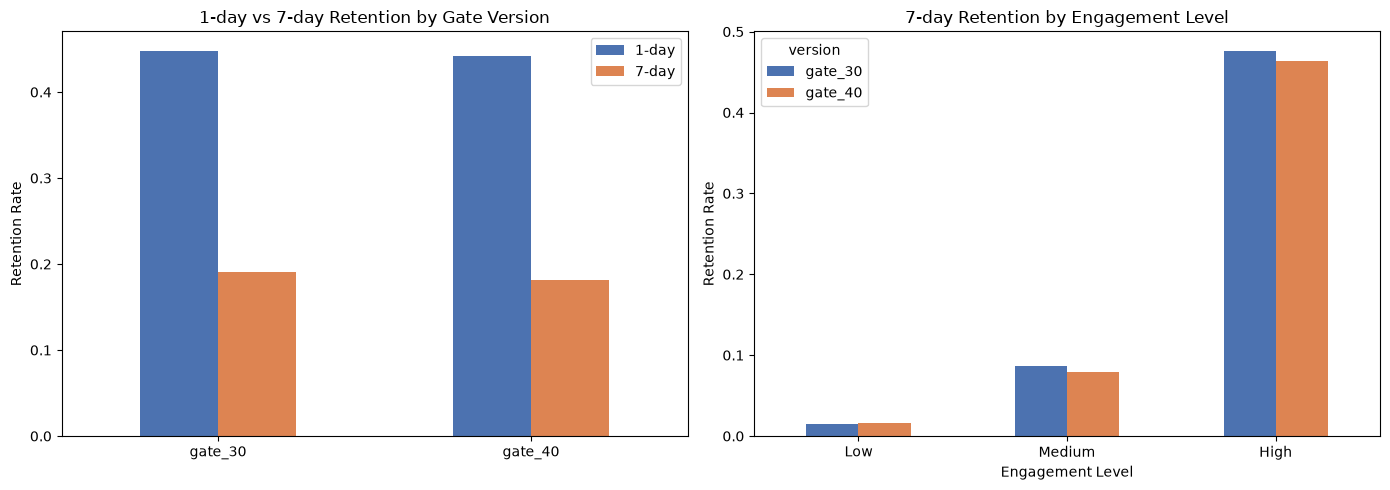

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Overall retention by group
retention_data = df_clean.groupby('version')[['retention_1', 'retention_7']].mean()
retention_data.plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'])
axes[0].set_title('1-day vs 7-day Retention by Gate Version')
axes[0].set_ylabel('Retention Rate')
axes[0].set_xlabel('')
axes[0].legend(['1-day', '7-day'])
axes[0].tick_params(axis='x', rotation=0)

# Chart 2: 7-day retention by engagement segment
segment_summary[['gate_30', 'gate_40']].plot(kind='bar', ax=axes[1], color=['#4C72B0', '#DD8452'])
axes[1].set_title('7-day Retention by Engagement Level')
axes[1].set_ylabel('Retention Rate')
axes[1].set_xlabel('Engagement Level')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('retention_charts.png', dpi=150)
plt.show()

## Summary & Recommendation

**Question:** Does moving the first gate from level 30 to level 40 affect player retention?

**Method:** Chi-square test of independence on 1-day and 7-day retention, comparing 
the gate_30 (control) and gate_40 (treatment) groups. One extreme outlier 
(49,854 rounds played) was excluded before analysis.

**Findings:**
- 1-day retention showed no statistically significant difference (p = 0.075)
- 7-day retention was significantly lower for gate_40 (p = 0.0016)
- The effect was not uniform: high-engagement players showed the largest 
  retention drop under gate_40, while low-engagement players were roughly 
  unaffected (or slightly favored gate_40)

**Recommendation:** Keep the gate at level 30. Moving it to level 40 appears 
to hurt long-term retention, particularly among the game's most engaged players 
— the segment with the highest lifetime value.

**Limitations:** This analysis only covers retention, not monetization or 
session length. It's also based on a single snapshot in time (2019), so 
player behavior patterns may not reflect current engagement norms.